# Time Series Forecasting: Baselines, Exponential Smoothing, ARIMA, and ARMAX

| Key              | Value |
|:-----------------|:------|
| **Course Codes** | BBT 4206 and BFS 4102 |
| **Course Names** | BBT 4206: Business Intelligence II (Week 7-9 of 13)<br>BFS 4102: Advanced Business Data Analytics (Week 1-3 of 13) |
| **Semester**     | September to December 2026 |
| **Lecturer**     | Allan Omondi |
| **Contact**      | aomondi@strathmore.edu |
| **Note**         | The lecture contains both theory and practice.<br/>This notebook forms part of the practice.<br/>It is intended for educational purposes only, and nothing in it is investment advice.<br/>Recommended citation: [BibTex](https://raw.githubusercontent.com/course-files/TimeSeriesForecastingandNeuralNetworks/refs/heads/main/RecommendedCitation.bib) |

## What you will learn in this notebook

By the end of this notebook you should be able to:

1. Build the **naive**, **drift**, **moving average** and **simple exponential smoothing** forecasts, and explain what each one assumes.
2. Fit an **ARIMA** model and an **ARMAX** model (ARIMA with extra predictors) with `statsmodels`, and choose the order using AIC.
3. Evaluate a model with **walk-forward validation**, one day ahead, on days it has never seen.
4. Explain why a model can look excellent on a chart and still be no better than "tomorrow equals today".
5. Explain what happens to a forecast, and to its uncertainty, when you forecast many days ahead (for example, 63 days).

**Prerequisites:** Notebooks 1 and 2, and the lecture slides on moving averages, exponential smoothing, ARIMA and SARIMA.

## The Rules of This Lab

Every model in Notebooks 3, 4, 6 and 7 is scored in the same way, so that the results can be compared fairly.

| Rule | Why |
|:-----|:----|
| The **target** is the next-day **log return**. We convert a forecast back into a closing price. | Notebook 2: returns are stationary, prices are not. |
| A model is fitted only on days **before** the days it is scored on. | Otherwise we are testing the model on what it has already seen. |
| The first training block has 1000 days. After that, the model is refitted every 63 days (about one quarter) on **all** the history so far (an expanding window), and then predicts the next 63 days. | This is **walk-forward validation**. It repeats the test through many different market conditions. |
| Every model is compared with the **naive forecast**: tomorrow's close equals today's close. | A forecast is only useful if it beats the cheapest alternative. |

The settings `INITIAL_TRAIN = 1000` and `TEST_SIZE = 63` are in `tslab/config.py`.

## Step 1: Set Up the Notebook

In [1]:
import os
import sys
import subprocess

print("Python interpreter:", sys.executable)
print("Python version    :", sys.version.split()[0])

# Google Colab starts with an empty workspace, so we fetch the lab files first.
# On your own computer this block does nothing.
if "google.colab" in sys.modules and not os.path.exists("tslab"):
    subprocess.run(["git", "clone", "https://github.com/course-files/TimeSeriesForecastingandNeuralNetworks.git"], check=True)
    os.chdir("TimeSeriesForecastingandNeuralNetworks")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements/colab.txt"], check=True)
    print("Colab workspace prepared.")

Python interpreter: C:\Users\aomondi\Documents\GitHub\Teaching\TimeSeriesForecastingandNeuralNetworks\.venv\Scripts\python.exe
Python version    : 3.12.10


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# Time series models from statsmodels
from statsmodels.tsa.api import SimpleExpSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

from tslab import config
from tslab.data import load_market_data
from tslab.features import make_dataset
from tslab.validation import walk_forward_splits, describe_splits
from tslab.metrics import compare_models, diebold_mariano, dm_verdict
from tslab.plots import plot_price_forecasts

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 5)

## Step 2: Prepare the Data and the Walk-Forward Folds

We use the same modelling table as the machine learning notebooks (it has the closing price and the next-day return for every day). In this notebook the classical models use only the columns they need: the price and, later, the other markets.

The last row of the table has no next-day return yet, because that day has not happened. We remove it for scoring.

In [3]:
frame = load_market_data()                       # raw market table
dataset = make_dataset(frame, horizon=1)         # features at day t, target for day t+1
dataset = dataset.dropna(subset=["target_return"])

splits = list(walk_forward_splits(len(dataset), config.INITIAL_TRAIN, config.TEST_SIZE))
print("Number of rows in the modelling table:", len(dataset))
print("Number of walk-forward folds         :", len(splits))
describe_splits(splits, dataset.index).head(5)

Loaded 2953 trading days of NVDA, 2015-01-02 to 2026-09-30, with 7 predictor series.
Number of rows in the modelling table: 2753
Number of walk-forward folds         : 28


,train_rows,train_from,train_to,test_rows,test_from,test_to
fold,,,,,,
1,1000,2015-10-16,2019-10-07,63,2019-10-08,2020-01-07
2,1063,2015-10-16,2020-01-07,63,2020-01-08,2020-04-07
3,1126,2015-10-16,2020-04-07,63,2020-04-08,2020-07-08
4,1189,2015-10-16,2020-07-08,63,2020-07-09,2020-10-06
5,1252,2015-10-16,2020-10-06,63,2020-10-07,2021-01-06


In [4]:
first_test_row = splits[0][1][0]
print("Scoring starts on:", dataset.index[first_test_row].date())
print("Scoring ends on  :", dataset.index[-1].date())

Scoring starts on: 2019-10-08
Scoring ends on  : 2026-09-29


Every model below is scored on the rows from the first test date to the end. The test period includes calm years and turbulent ones, which is exactly what we want.

We will store each model's predicted **return** for each test day in a dictionary called `predictions`. A prediction of 0 means "no change".

In [5]:
predictions = {}      # model name -> Series of predicted next-day returns (NaN outside the test blocks)

def empty_series():
    return pd.Series(np.nan, index=dataset.index)

log_close = np.log(frame["Close"])          # full price history, one value per trading day
position_in_frame = {date: i for i, date in enumerate(frame.index)}

## Step 3: Baseline Forecasts

Before any clever model, build the simple ones. They set the bar that the clever models must clear.

### 3.1 The Naive Forecast (Random Walk)

> **Tomorrow's close equals today's close.** In terms of returns: predict a return of **zero**.

This forecast is not silly. If prices follow a random walk (the market has already absorbed all available information), it is the **best possible** forecast. It costs nothing to build. A model that cannot beat it is useless.

### 3.2 The Drift Forecast

> Tomorrow's return equals the **average daily return in the training data**.

This adds a small steady upward drift to the naive forecast, because stocks have tended to rise over long periods.

In [6]:
# Naive forecast: always zero return (it is added automatically by compare_models, so we do not store it)

# Drift forecast: the average return in the training block, recomputed at every fold
drift = empty_series()
for train_idx, test_idx in splits:
    drift.iloc[test_idx] = dataset["target_return"].iloc[train_idx].mean()
predictions["Drift"] = drift

### 3.3 The Moving Average Forecast

> Tomorrow's close equals the **average of the last k closing prices**.

A moving average smooths noise, but it always **lags** the price. In a trending market it is systematically too low (or too high). We use a 20-day window.

In [7]:
window = 20
moving_average_price = frame["Close"].rolling(window).mean().reindex(dataset.index)
ma_prediction = np.log(moving_average_price / dataset["close"])    # implied return

moving_average = empty_series()
for _, test_idx in splits:
    moving_average.iloc[test_idx] = ma_prediction.iloc[test_idx]
predictions["Moving average (20 days)"] = moving_average

### 3.4 Simple Exponential Smoothing (SES)

> Tomorrow's close equals a **weighted average of all past closes**, with weights that shrink exponentially into the past.

The key number is `alpha`, between 0 and 1. A large alpha puts nearly all the weight on today's price (the forecast reacts quickly). A small alpha spreads the weight over a long history (the forecast is smooth but slow). The recursion is only one line:

`level_today = alpha * price_today + (1 - alpha) * level_yesterday`

and the forecast for tomorrow is `level_today`. `statsmodels` estimates alpha from the training block for us. Then we apply the recursion to all the days up to today (we are using today's price, which we know).

In [8]:
ses = empty_series()
alphas = []
for train_idx, test_idx in splits:
    last_train_date = dataset.index[train_idx[-1]]
    train_prices = frame["Close"].loc[:last_train_date]

    alpha = SimpleExpSmoothing(train_prices, initialization_method="estimated").fit().params["smoothing_level"]
    alphas.append(alpha)

    # Run the recursion with that alpha, from the start of the history to the end of the test block
    level = frame["Close"].iloc[0]
    levels = []
    for price in frame["Close"].values:
        level = alpha * price + (1 - alpha) * level
        levels.append(level)
    levels = pd.Series(levels, index=frame.index)

    ses.iloc[test_idx] = np.log(levels.reindex(dataset.index).iloc[test_idx] / dataset["close"].iloc[test_idx])
predictions["Simple exponential smoothing"] = ses

print("Estimated alpha in each fold (first five):", np.round(alphas[:5], 3))

Estimated alpha in each fold (first five): [0.971 0.967 0.873 0.872 0.874]


Look at the alpha values. For a stock price, they are usually **very close to 1**. The optimiser is telling you something important: the best weight to put on yesterday's level is almost all of it. In other words, the best exponential smoothing forecast of a stock price is almost the naive forecast. Holt's method and Holt-Winters add a trend and a seasonal term; they inherit the same difficulty.

## Step 4: ARIMA

ARIMA(p, d, q) combines three ideas, all from the lecture:

- **AR(p)**: tomorrow depends on the last *p* values of the series itself.
- **I(d)**: the series is differenced *d* times to make it stationary.
- **MA(q)**: tomorrow depends on the last *q* forecast errors.

We fit the model to the **log price** with `d = 1`, so the model works on the log return internally (Notebook 2).

### Choosing p and q with AIC

The **Akaike Information Criterion (AIC)** rewards fit and penalises complexity. Lower is better. We search a small grid of orders, using **only the first training block**, so that we do not use information from the test period to choose the model.

In [9]:
first_train_end_date = dataset.index[splits[0][0][-1]]
first_block = log_close.loc[:first_train_end_date]

rows = []
for p in range(0, 4):
    for q in range(0, 4):
        try:
            result = ARIMA(first_block, order=(p, 1, q)).fit()
            rows.append({"p": p, "d": 1, "q": q, "AIC": result.aic})
        except Exception:
            pass
aic_table = pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)
display(aic_table.head(5))
best_p, _, best_q = aic_table.loc[0, ["p", "d", "q"]].astype(int)
print(f"Chosen order: ARIMA({best_p}, 1, {best_q})")

,p,d,q,AIC
0,0,1,0,-5248.529826
1,0,1,3,-5248.079246
2,3,1,0,-5247.719356
3,2,1,2,-5246.934367
4,1,1,0,-5246.869576


Chosen order: ARIMA(0, 1, 0)


Differences in AIC smaller than about 2 are not meaningful. If several orders are within 2 of the best, the simplest one is as good as the rest.

Now we run the walk-forward test. At each fold we **refit** the model on all the history so far, then use `apply` to carry the fitted parameters through the test block. For each test day the model sees the real prices up to that day and forecasts the next day (a **one-step-ahead** forecast with fixed parameters).

In [10]:
arima = empty_series()
for train_idx, test_idx in splits:
    last_train_pos = position_in_frame[dataset.index[train_idx[-1]]]
    first_test_pos = position_in_frame[dataset.index[test_idx[0]]]
    last_test_pos = position_in_frame[dataset.index[test_idx[-1]]]

    fitted = ARIMA(log_close.iloc[: last_train_pos + 1], order=(best_p, 1, best_q)).fit()

    # Carry the parameters through the test block (plus one day, because we forecast one day ahead)
    carried = fitted.apply(log_close.iloc[: last_test_pos + 2], refit=False)
    one_step = carried.get_prediction(start=first_test_pos + 1, end=last_test_pos + 1).predicted_mean

    today = log_close.iloc[first_test_pos : last_test_pos + 1].values
    arima.iloc[test_idx] = one_step.values - today
predictions[f"ARIMA({best_p},1,{best_q})"] = arima

## Step 5: ARMAX, ARIMA with Multiple Predictors

So far every model used the stock's own past. ARIMA can also include **exogenous** predictors (the "X"): other series that are not forecast by the model but are used to help explain it.

We model the stock's daily **return** `r(s)` as

`r(s) = constant + (AR term on its own past) + b1 * SP500 return(s-1) + b2 * TECH return(s-1) + ...`

Notice the subscript **s-1** on every predictor. The predictors are **shifted by one day**, so the value used to forecast the stock's return on day *s* was already known at the close of day *s-1*. If you forget this shift, you are using today's market move to explain today's stock move. That is look-ahead bias, and your results will be spectacular and false.

In [11]:
# Daily changes of each predictor market (returns for prices, difference for the interest rate)
predictor_changes = pd.DataFrame(index=frame.index)
for name in ["SP500", "TECH", "GOLD", "BRENT", "USD", "VIX"]:
    predictor_changes[name] = np.log(frame[name]).diff()
predictor_changes["US10Y"] = frame["US10Y"].diff()

# THE SHIFT: the predictors used for day s are the ones from day s-1
exog_all = predictor_changes.shift(1)
stock_return = log_close.diff()

display(pd.concat([stock_return.rename("stock return on day s"), exog_all.add_suffix(" (day s-1)")], axis=1).dropna().head(3).round(4).T)

Date,2015-01-06,2015-01-07,2015-01-08
stock return on day s,-0.0308,-0.0026,0.0369
SP500 (day s-1),-0.0184,-0.0089,0.0116
TECH (day s-1),-0.0154,-0.0121,0.0084
GOLD (day s-1),0.0150,0.0127,-0.0072
BRENT (day s-1),-0.0605,-0.0386,0.0010
USD (day s-1),0.0033,0.0013,0.0043
VIX (day s-1),0.1131,0.0585,-0.0896
US10Y (day s-1),-0.0840,-0.0760,-0.0090


In [12]:
FIRST_USABLE = 2   # position 0 has no return, and position 1 has no lagged predictors (they need a return on day 0)

def walk_forward_arma(use_exog, ar_order=1):
    """
    One-step-ahead walk-forward forecasts of the daily return with an ARMA model,
    with or without the extra predictors. Returns a Series of predicted returns
    indexed like the modelling table.
    """
    output = empty_series()
    for train_idx, test_idx in splits:
        last_train_pos = position_in_frame[dataset.index[train_idx[-1]]]
        first_test_pos = position_in_frame[dataset.index[test_idx[0]]]
        last_test_pos = position_in_frame[dataset.index[test_idx[-1]]]

        # Fit on the training block only
        y_train = stock_return.iloc[FIRST_USABLE : last_train_pos + 1]
        x_train = exog_all.iloc[FIRST_USABLE : last_train_pos + 1] if use_exog else None
        fitted = SARIMAX(y_train, exog=x_train, order=(ar_order, 0, 0), trend="c").fit(disp=False)

        # Carry the fitted parameters through the test block, plus one more day,
        # because the prediction made on day t is for day t+1.
        y_all = stock_return.iloc[FIRST_USABLE : last_test_pos + 2]
        x_all = exog_all.iloc[FIRST_USABLE : last_test_pos + 2] if use_exog else None
        carried = fitted.apply(y_all, exog=x_all, refit=False)

        # Positions inside y_all are shifted by FIRST_USABLE relative to the full table.
        start = first_test_pos + 1 - FIRST_USABLE
        end = last_test_pos + 1 - FIRST_USABLE
        output.iloc[test_idx] = carried.get_prediction(start=start, end=end).predicted_mean.values
    return output

predictions["ARMA(1,0), own past only"] = walk_forward_arma(use_exog=False)
predictions["ARMAX(1,0), 7 predictors"] = walk_forward_arma(use_exog=True)

Two models in that cell deserve a close look.

- `ARMA(1,0), own past only` is a univariate model of the return. It is the "ARIMA with one input" of earlier versions of this lab.
- `ARMAX(1,0), 7 predictors` is the same model plus the seven other markets (yesterday's moves). Comparing the two shows you exactly what the extra predictors add.

## Step 6: Compare the Models

`compare_models` converts every predicted return into a predicted **closing price** (`close today * exp(predicted return)`) and scores it against the actual next close on exactly the same days. It adds the naive forecast for us.

| Measure | Meaning |
|:--------|:--------|
| **RMSE ($)** and **MAE ($)** | Typical size of the error, in the currency of the price. RMSE punishes large errors more. |
| **MAPE (%)** | The error as a percentage of the price. |
| **Directional accuracy** | The share of days on which the model got the up or down direction right. A coin toss scores about 50 percent. |
| **Out-of-sample R2 (returns)** | How much better than the zero-return forecast the model is, in terms of squared error on returns. Above 0 beats the naive forecast; below 0 is worse than it. |

In [13]:
scores = compare_models(dataset, predictions)
scores.round(4)

,RMSE ($),MAE ($),MAPE (%),Directional accuracy,Out-of-sample R2 (returns)
Naive (no change),2.6779,1.5131,2.3472,NaN,0.0000
Drift,2.6780,1.5088,2.3401,0.5431,0.0043
Moving average (20 days),5.9582,3.7456,6.2856,0.4974,-5.4571
Simple exponential smoothing,2.6734,1.5138,2.3474,0.4991,0.0035
"ARIMA(0,1,0)",2.6779,1.5131,2.3472,NaN,0.0000
"ARMA(1,0), own past only",2.6685,1.5081,2.3418,0.5379,0.0081
"ARMAX(1,0), 7 predictors",2.6984,1.5099,2.3338,0.5396,0.0101


Read the table in this order:

1. Find the row for the **naive** forecast. Its RMSE is the number to beat.
2. For each other row, ask: is the RMSE lower than the naive RMSE, and by how much?
3. Look at the **out-of-sample R2**. A model that does not beat the naive forecast has a value at or below zero.
4. Look at directional accuracy. Is it meaningfully above 50 percent?

A very small difference in RMSE could easily be luck. We use the **Diebold-Mariano test** to decide. Its null hypothesis is that two forecasts are equally accurate. A p-value below 0.05 suggests a real difference. In the output, a **negative** statistic means that the model has the smaller error.

In [14]:
scored_rows = pd.concat(predictions, axis=1).dropna().index
actual_return = dataset.loc[scored_rows, "target_return"]

dm_rows = []
for name, series in predictions.items():
    statistic, p_value = diebold_mariano(actual_return, series.loc[scored_rows], np.zeros(len(scored_rows)))
    dm_rows.append({"Model (against naive)": name, "DM statistic": statistic, "p-value": p_value,
                    "Verdict": dm_verdict(statistic, p_value)})
pd.DataFrame(dm_rows).set_index("Model (against naive)").round(4)

,DM statistic,p-value,Verdict
Model (against naive),,,
Drift,-1.3607,0.1738,No significant difference
Moving average (20 days),24.5748,0.0000,Significantly WORSE than naive
Simple exponential smoothing,-0.9559,0.3393,No significant difference
"ARIMA(0,1,0)",0.0757,0.9396,No significant difference
"ARMA(1,0), own past only",-1.4957,0.1349,No significant difference
"ARMAX(1,0), 7 predictors",-0.9320,0.3515,No significant difference


Whatever the outcome, do not skip the question "is it significant?". Reporting that one model has an RMSE of 2.31 and another 2.33 without a test is reporting noise as if it were a finding.

## Step 7: A Forecast That Looks Perfect But Is Not

Plot the ARIMA one-step forecast of the closing price against the actual closing price for the most recent 250 days.

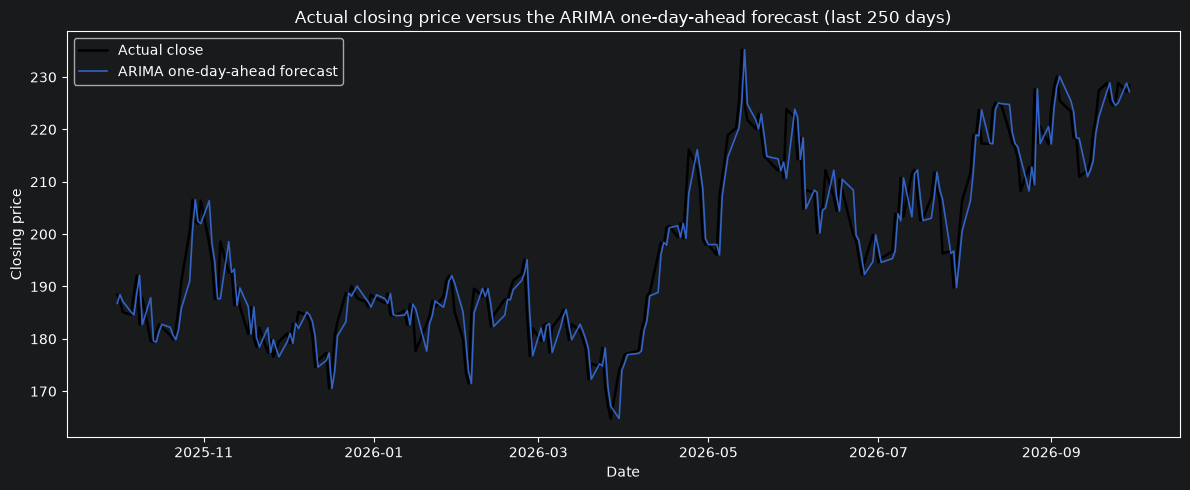

In [15]:
scored = dataset.loc[scored_rows]
arima_price = scored["close"] * np.exp(predictions[f"ARIMA({best_p},1,{best_q})"].loc[scored_rows])

# The prediction made on day t is for day t+1, so we label it with the date of day t+1
next_day_labels = scored.index.to_series().shift(-1)
plot_price_forecasts(
    dates=scored.index, actual=scored["target_close"].values,
    forecasts={"ARIMA one-day-ahead forecast": arima_price.values},
    title="Actual closing price versus the ARIMA one-day-ahead forecast (last 250 days)",
    last_n=250,
)

The two lines are almost on top of each other. It looks as if the model is predicting the price remarkably well. Now zoom in on the last **30** days.

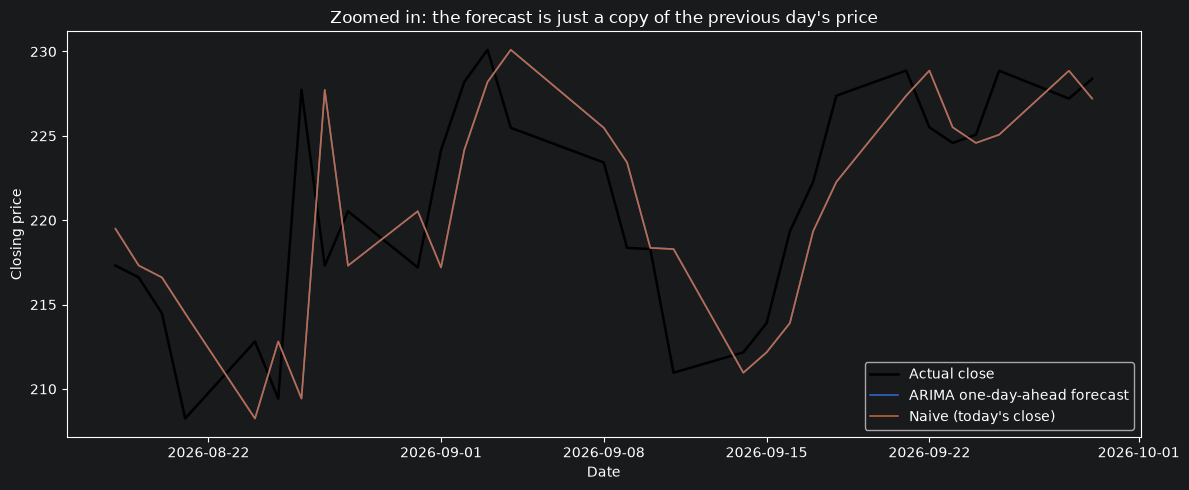

In [16]:
plot_price_forecasts(
    dates=scored.index, actual=scored["target_close"].values,
    forecasts={"ARIMA one-day-ahead forecast": arima_price.values, "Naive (today's close)": scored["close"].values},
    title="Zoomed in: the forecast is just a copy of the previous day's price",
    last_n=30,
)

At this scale you can see what is happening. Whenever the actual price jumps, the forecast jumps **one day later**. The forecast is a **delayed copy** of the actual series. The ARIMA line and the naive line are almost identical. (With the data used in this lab, the AIC search picks ARIMA(0,1,0), which is exactly the naive forecast. If your stock gives a different order, expect a very small difference instead of none.)

This is the single most common mistake in student forecasting work. A chart of a price forecast against the actual price always looks good, because a price changes by only a small percentage in one day. The eye cannot see an error of 1 percent on a chart that spans a 300 percent range. Never judge a forecast from the chart alone. **Always compare the error with the naive forecast's error.**

(Many published tutorials that "predict stock prices with an LSTM" show exactly this delayed-copy pattern and call it a success. In Notebook 6 you will reproduce that mistake on purpose and then fix it.)

## Step 8: Residual Diagnostics

If a model has captured all the linear structure in the data, its **residuals** (the forecast errors) should look like random noise: no autocorrelation. We test the final ARIMA fit with the Ljung-Box test, whose null hypothesis is "no autocorrelation in the residuals".

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2         0.0009   1.13e-05     80.753      0.000       0.001       0.001


,Statistic,p-value
5,22.034124,0.000516
10,39.943424,0.000017
21,53.777151,0.000106


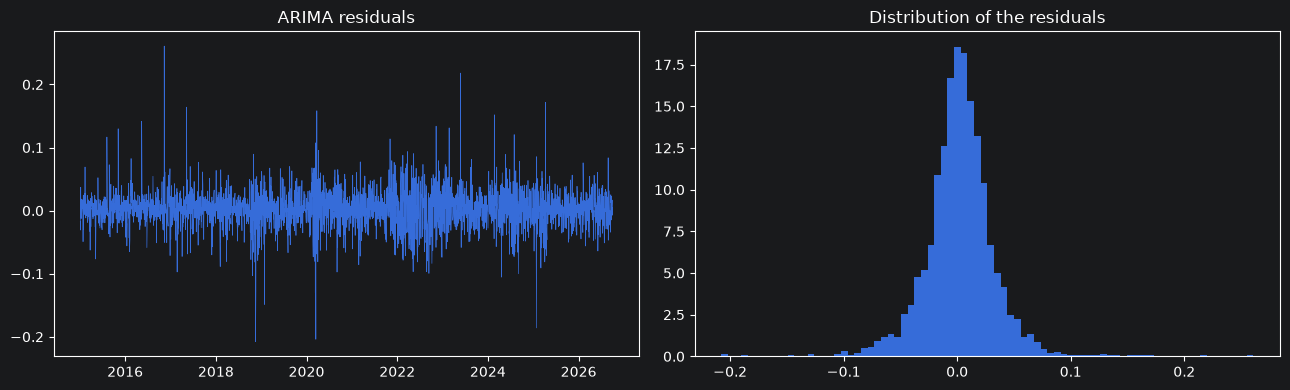

In [17]:
final_arima = ARIMA(log_close.to_numpy(), order=(best_p, 1, best_q)).fit()
print(final_arima.summary().tables[1])

residuals = pd.Series(final_arima.resid[1:], index=log_close.index[1:])
display(acorr_ljungbox(residuals, lags=[5, 10, 21], return_df=True).rename(columns={"lb_stat": "Statistic", "lb_pvalue": "p-value"}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(residuals, linewidth=0.5); axes[0].set_title("ARIMA residuals")
axes[1].hist(residuals, bins=80, density=True); axes[1].set_title("Distribution of the residuals")
plt.tight_layout(); plt.show()

Look at the p-values. If they are small, as they are for AAPL at lags 10 and 21, some linear structure remains that a low-order ARIMA did not capture, yet we saw above that the extra complexity did not help out of sample. If they are large, the residuals pass the test. Either way, a model's residuals can pass the Ljung-Box test and still be **bad forecasts**. Passing says only that no **linear** pattern is left. The residuals above also show volatility clustering (Notebook 2), which no ARIMA model can capture, because ARIMA assumes a constant error variance.

## Step 9: What Happens When We Forecast 63 Days Ahead?

Earlier versions of this lab asked for a forecast of the next 63 business days (one quarter). Let us do that with ARIMA, and look carefully at what comes out.

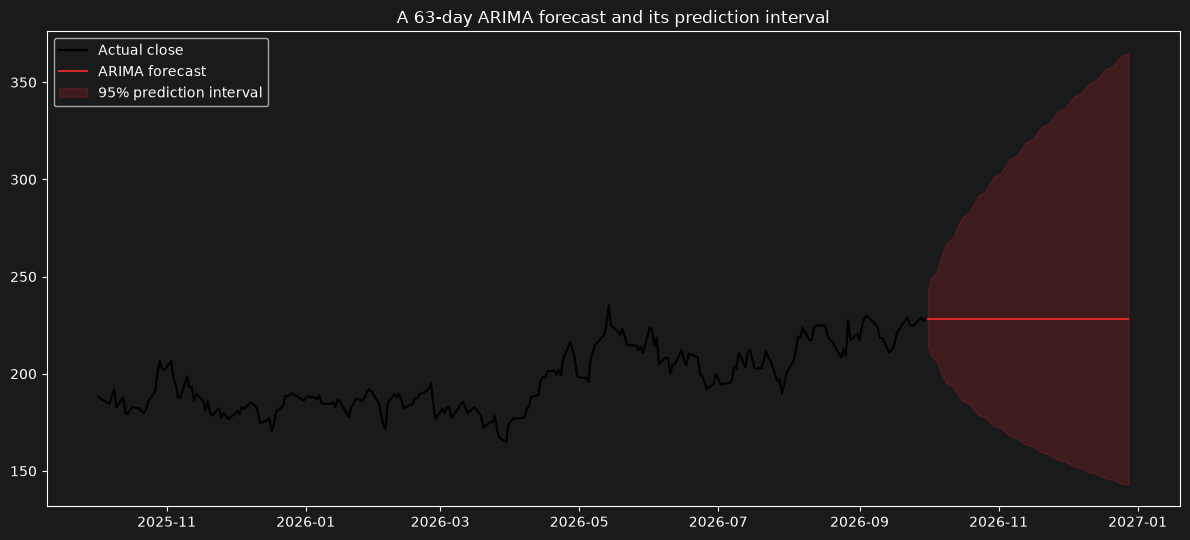

Last actual close          : 228.38
Forecast in 63 days        : 228.38
95% interval in 63 days    : 142.87 to 365.08


In [18]:
horizon = 63
long_forecast = final_arima.get_forecast(steps=horizon)
mean_log_price = long_forecast.predicted_mean
interval = long_forecast.conf_int(alpha=0.05)

future_dates = pd.bdate_range(start=frame.index[-1] + pd.offsets.BDay(1), periods=horizon)
forecast_price = pd.Series(np.exp(mean_log_price), index=future_dates)
lower = pd.Series(np.exp(interval[:, 0]), index=future_dates)
upper = pd.Series(np.exp(interval[:, 1]), index=future_dates)

recent = frame["Close"].iloc[-250:]
plt.figure(figsize=(12, 5.5))
plt.plot(recent, color="black", label="Actual close")
plt.plot(forecast_price, color="tab:red", label="ARIMA forecast")
plt.fill_between(future_dates, lower, upper, color="tab:red", alpha=0.2, label="95% prediction interval")
plt.title("A 63-day ARIMA forecast and its prediction interval")
plt.legend(); plt.tight_layout(); plt.show()

print(f"Last actual close          : {frame['Close'].iloc[-1]:.2f}")
print(f"Forecast in 63 days        : {forecast_price.iloc[-1]:.2f}")
print(f"95% interval in 63 days    : {lower.iloc[-1]:.2f} to {upper.iloc[-1]:.2f}")

Look at the shape of the forecast. The central forecast is a **straight line**: for a model with no autoregressive memory it is exactly flat at today's price, and for a model with some memory it flattens within a few days. Nothing is left but the drift. And the **interval widens** with the square root of the horizon: after a quarter, the 95 percent range is very wide relative to any change in the central forecast.

This is not a weakness of ARIMA. It is the honest answer. The further ahead you look, the less you know. A model that gives you a precise-looking 63-day price path without an interval is hiding that uncertainty from you.

This is why, in Notebook 7, we forecast several horizons separately, **report their uncertainty**, and test how the skill of the models falls as the horizon grows.

## Step 10: Save the Predictions

We save the predicted returns, so that Notebook 6 can compare the neural networks with these classical models on the very same days.

In [19]:
os.makedirs(config.OUTPUT_DIR, exist_ok=True)
saved = pd.concat(predictions, axis=1)
saved.to_csv(config.OUTPUT_DIR / "predictions_classical.csv")
print("Saved", saved.dropna().shape[0], "rows to", config.OUTPUT_DIR / "predictions_classical.csv")

Saved 1753 rows to C:\Users\aomondi\Documents\GitHub\Teaching\TimeSeriesForecastingandNeuralNetworks\outputs\predictions_classical.csv


## Step 11: Exercises

1. Which model has the lowest RMSE? Is it significantly better than the naive forecast according to the Diebold-Mariano test? Write one sentence that a manager could understand.
2. In the SES section, what does an alpha close to 1 say about the series?
3. Compare `ARMA(1,0), own past only` with `ARMAX(1,0), 7 predictors`. Did the extra predictors improve the out-of-sample R2? Offer one possible reason for your finding.
4. Remove the `.shift(1)` in Step 5 (so that the predictors are from day s instead of s-1), and run the comparison again. What happens to the R2 and the directional accuracy? Why is the result worthless, even though it looks wonderful?
5. Add a SARIMA model with `seasonal_order=(1, 0, 0, 5)` (a weekly pattern). Does it improve on ARMA(1,0)? Does your answer agree with Notebook 2, Step 8?
6. Change the moving average window in Step 3.3 from 20 to 5, and then to 60. How does the lag change, and why?
7. In Step 9, the interval grows with the horizon. By what factor does the width at day 63 exceed the width at day 1? (Hint: what is the square root of 63?)

## Summary

- Always start with the naive forecast. In an efficient market it is hard to beat.
- Exponential smoothing and ARIMA applied to a stock price tend to return something very close to the naive forecast.
- Adding predictors (ARMAX) gives the model more information, but you must use only information available **before** the day you are forecasting, and you must test whether it helps.
- A chart of a forecast overlaid on the actual price can be deeply misleading. Compare errors with the naive error, and test the difference.
- Long-horizon forecasts are flat lines with a wide interval around them. Report the interval.